# 01_descriptive: Descriptive statistics

**Lead:** Minh Vu · **Plan:** `docs/Go.md` stage 2, WBS C1.1, C1.5–C1.7 · **Slides:** Chap 1 §3–4

All code lives in **`src/descriptive_stats.py`**, split into classes:

| Class | Job |
|---|---|
| `DescConfig` | Shared settings: tiers, variable lists, colours, figure folder |
| `DescriptiveData` | Reads 3 processed tables, filters rows, adds the `temp` and `condition` labels |
| `MeasurementScales` | Scale of measurement of every column, with the reason (C1.1) |
| `SummaryStats` | Table of descriptive measures (Chap 1, p. 57), for a whole table or split by group |
| `DescriptivePlots` | 6 figures (Go.md 2.2) |
| `InsightWriter` | Insights following p. 60; **every number in the sentences is computed from the data** |
| `DescriptiveAnalysis` | Calls the classes above in order |

**Outputs:** 6 figures `reports/figures/desc_*.png`. Run with Restart & Run All, or `python src/descriptive_stats.py`.

## 1. Set-up and data

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "protocol.py").exists())
sys.path.insert(0, str(ROOT / "src"))
from descriptive_stats import DescriptiveAnalysis

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 200)
a = DescriptiveAnalysis()          # reads the data when it is created
d = a.data
print("repository root:", ROOT.name)

repository root: ProjectThongKe


**Which rows are used.** The cycle level keeps only batteries whose conditions do **not** change (tiers A, B, N) and drops the rows flagged `cap_outlier` (abnormal capacity) or `break_in` (start-up phase). This is the same filter as `Introduction_of_dataset.md` section 8, so the numbers recorded there can be reproduced.

In [2]:
clean = d.all_clean
print("cycles_clean.csv:", len(clean), "rows")
print("in tiers A/B/N:", clean.tier.isin(a.cfg.tiers).sum())
print("after dropping cap_outlier and break_in:", len(d.cycles), "rows,", d.cycles.battery_id.nunique(), "batteries")
assert len(d.cycles) == 2065 and len(d.batteries) == 23       # matches Introduction_of_dataset section 8
d.batteries.groupby(["tier"]).battery_id.apply(lambda s: ", ".join(s)).to_frame("batteries")

cycles_clean.csv: 2658 rows
in tiers A/B/N: 2121
after dropping cap_outlier and break_in: 2065 rows, 23 batteries


,batteries
tier,
A,"B0005, B0006, B0007, B0018, B0033, B0034, B0045, B0046, B0047, B0048, B0055, B0056"
B,"B0025, B0026, B0027, B0028, B0029, B0030, B0031, B0032, B0036, B0053"
N,B0054


## 2. Data classification (WBS C1.1, Chap 1, pp. 13–14, 22–32)

- **Structure:** the raw data are *semi-structured* (nested MATLAB structs) and were flattened into *structured* tables during preprocessing.
- **Data type: panel data.** The cross-section units are the batteries; each battery is a time series over cycles (`cycle_valid`). This drives every method choice: cycles within a battery depend on each other, so tests between conditions must use the **battery** as the unit of observation.
- **Scale of measurement of every column** of the three tables used here (`cycles_clean.csv`, `battery_fade.csv`, `battery_summary.csv`, plus the two labels added in this notebook). The table follows the data dictionary (`Introduction_of_dataset.md` section 6); the only deliberate difference is `chg_end_time`, a timestamp, classed as Interval like `start_time`. The code stops if any column has no scale.

In [3]:
scales = a.scale_table()
print(scales.scale.value_counts().to_string())
scales

scale
Ratio               24
Ratio (discrete)    15
Nominal              9
Interval             8
Ordinal              1


,column,tables,scale,valid operations,reason
0,battery_id,"cycles_clean, battery_fade, battery_summary",Nominal,"count, mode, frequency table","label that identifies or groups; only counts, mode and frequency tables make sense"
1,break_in,cycles_clean,Nominal,"count, mode, frequency table",yes/no flag (bool); only counts and shares make sense
2,cap_outlier,cycles_clean,Nominal,"count, mode, frequency table",yes/no flag (bool); only counts and shares make sense
3,condition,"cycles_clean, battery_fade",Nominal,"count, mode, frequency table","label that identifies or groups; only counts, mode and frequency tables make sense"
4,group,"cycles_clean, battery_fade, battery_summary",Nominal,"count, mode, frequency table","label that identifies or groups; only counts, mode and frequency tables make sense"
5,long_rest,cycles_clean,Nominal,"count, mode, frequency table",yes/no flag (bool); only counts and shares make sense
6,profile,"cycles_clean, battery_fade, battery_summary",Nominal,"count, mode, frequency table","label that identifies or groups; only counts, mode and frequency tables make sense"
7,temp,"cycles_clean, battery_fade",Nominal,"count, mode, frequency table",label of the ambient group (4°C / 24°C / 43°C)
8,tier,"cycles_clean, battery_fade, battery_summary",Nominal,"count, mode, frequency table",quality class A/B/C/N/X; the letters are not ordered by a measured quantity
9,segment,cycles_clean,Ordinal,"+ order, median, percentiles","1st, 2nd, ... block of constant conditions: ordered, but the steps are not equal amounts"


Two consequences used later: temperatures (Interval) are compared with differences, never with ratios ("43°C is twice as hot as 22°C" is wrong); SOH, capacity, resistance and rest time (Ratio) can be compared with ratios ("Rct rose by a factor of 1.5").

## 3. Descriptive tables (WBS C1.5)

Measures follow slide Chap 1, p. 57. **Kurtosis has 3 added** (Pearson, normal = 3), because pandas returns excess kurtosis (normal = 0).

### 3.1 Cycle level (one row of the source table = one discharge)

In [4]:
a.cycle_table().round(4)

,n,n_missing,mean,median,Q1,Q3,SD,SE,min,max,range,skewness,kurtosis
capacity_int_Ah,2065.0,0.0,1.5064,1.5121,1.3215,1.7165,0.2543,0.0056,0.7461,2.0467,1.3006,-0.5194,2.9209
soh,2065.0,0.0,0.8771,0.8859,0.8216,0.9492,0.0868,0.0019,0.5756,1.0413,0.4658,-0.6428,3.0746
T_max_C,2065.0,0.0,36.8441,38.7261,21.2008,51.4464,15.6624,0.3447,10.1963,63.0242,52.8279,-0.1348,1.9537
Re_ohm,2008.0,57.0,0.0816,0.0789,0.0631,0.1015,0.0244,0.0005,0.0276,0.1383,0.1107,0.0691,2.2954
Rct_ohm,2008.0,57.0,0.1275,0.1228,0.0864,0.1667,0.0489,0.0011,0.0395,0.2524,0.2128,0.4444,2.2786
rest_before_h,2065.0,0.0,3.1873,0.0240,0.0205,0.5567,19.8295,0.4364,0.0177,303.9284,303.9108,10.6031,136.9460


In [5]:
miss = d.cycles[d.cycles.Re_ohm.isna()]
print(f"Re_ohm / Rct_ohm missing: {len(miss)} rows, in", miss.groupby("battery_id").size().to_dict(),
      "(the first cycles of these batteries come before the first EIS measurement)")

Re_ohm / Rct_ohm missing: 57 rows, in {'B0005': 19, 'B0006': 19, 'B0007': 19} (the first cycles of these batteries come before the first EIS measurement)


### 3.2 Split by ambient temperature

Pooled `T_max_C` has kurtosis < 3 and several peaks, because it mixes 3 ambient temperatures (Go.md 2.1), so it is described per group:

In [6]:
order = a.cfg.temp_order
display(a.stats.by_group(d.cycles, "T_max_C", "temp", order).round(2))
display(a.stats.by_group(d.cycles, "soh", "temp", order).round(4))

,n,n_missing,mean,median,Q1,Q3,SD,SE,min,max,range,skewness,kurtosis
temp,,,,,,,,,,,,,
4°C,602.0,0.0,16.09,15.04,13.23,18.65,3.99,0.16,10.20,25.40,15.20,0.65,2.57
24°C,1307.0,0.0,43.45,40.58,38.04,52.79,8.08,0.22,25.38,61.14,35.76,0.66,2.26
43°C,156.0,0.0,61.53,61.82,60.32,62.43,1.03,0.08,59.59,63.02,3.44,-0.53,1.83


,n,n_missing,mean,median,Q1,Q3,SD,SE,min,max,range,skewness,kurtosis
temp,,,,,,,,,,,,,
4°C,602.0,0.0,0.8688,0.8647,0.8210,0.9183,0.0660,0.0027,0.7222,1.0413,0.3191,0.0843,2.3757
24°C,1307.0,0.0,0.8727,0.8839,0.8142,0.9564,0.0956,0.0026,0.5756,1.0252,0.4496,-0.6532,2.8327
43°C,156.0,0.0,0.9463,0.9492,0.9178,0.9723,0.0337,0.0027,0.8759,1.0108,0.1349,-0.0921,2.0458


> ⚠ **Do not read the SOH-by-temperature table as "heat keeps batteries healthy".** The 43°C batteries (group G3) have the highest mean SOH only because this group **ran the fewest cycles** and had no time to age, while the 4°C and 24°C groups ran much longer. The longest series of each group is printed below. To compare ageing between conditions, use the **battery-level degradation rate** (section 3.5), not the cycle-level mean SOH.

In [7]:
d.cycles.groupby("temp").cycle_valid.max().reindex(order).to_frame("longest series of one battery (cycles)")

,longest series of one battery (cycles)
temp,
4°C,101
24°C,196
43°C,39


### 3.3 Cycle level, split by operating condition

Operating condition = ambient temperature × discharge current × discharge profile. These tables describe each variable within each condition. They are still cycle-level summaries (cycles of one battery are dependent), so they describe, they do not test.

In [8]:
for var, t in a.cycle_tables_by_condition().items():
    print(f"\n{var}")
    display(t[["n", "mean", "median", "SD", "SE", "min", "max", "skewness", "kurtosis"]].round(4))


soh


,n,mean,median,SD,SE,min,max,skewness,kurtosis
condition,,,,,,,,,
"4°C, 1 A, CC",271.0,0.8444,0.8268,0.0720,0.0044,0.7240,1.0413,0.6007,2.4705
"4°C, 2 A, CC",331.0,0.8888,0.8847,0.0529,0.0029,0.7222,1.0282,0.0575,2.9180
"24°C, 2 A, CC",826.0,0.8584,0.8823,0.1066,0.0037,0.5756,1.0063,-0.5290,2.2813
"24°C, 2 A, square wave",28.0,0.9808,0.9832,0.0128,0.0024,0.9517,1.0001,-0.4307,2.3717
"24°C, 4 A, CC",372.0,0.8717,0.8549,0.0526,0.0027,0.7831,1.0252,0.6217,2.3678
"24°C, 4 A, square wave",81.0,0.9851,0.9854,0.0121,0.0013,0.9484,1.0035,-0.6917,2.9822
"43°C, 4 A, CC",156.0,0.9463,0.9492,0.0337,0.0027,0.8759,1.0108,-0.0921,2.0458



T_max_C


,n,mean,median,SD,SE,min,max,skewness,kurtosis
condition,,,,,,,,,
"4°C, 1 A, CC",271.0,13.2505,13.1025,2.0346,0.1236,10.1963,16.8789,0.1634,1.6506
"4°C, 2 A, CC",331.0,18.4231,18.2922,3.6716,0.2018,12.5082,25.3991,0.3082,1.8846
"24°C, 2 A, CC",826.0,38.6268,38.7898,2.6713,0.0929,25.3762,42.3325,-2.5199,13.0649
"24°C, 2 A, square wave",28.0,31.7940,31.7623,0.3501,0.0662,31.1782,32.5061,0.1866,2.1120
"24°C, 4 A, CC",372.0,55.5032,55.5470,2.2294,0.1156,50.4762,61.1372,-0.1437,1.9472
"24°C, 4 A, square wave",81.0,41.3838,41.2910,1.0410,0.1157,39.4569,43.2087,0.0955,1.8783
"43°C, 4 A, CC",156.0,61.5310,61.8200,1.0313,0.0826,59.5881,63.0242,-0.5279,1.8267



rest_before_h


,n,mean,median,SD,SE,min,max,skewness,kurtosis
condition,,,,,,,,,
"4°C, 1 A, CC",271.0,4.7447,0.0242,16.6910,1.0139,0.0224,73.1594,3.6364,14.5894
"4°C, 2 A, CC",331.0,2.4757,0.0208,11.8077,0.6490,0.0179,80.2293,5.4710,32.8390
"24°C, 2 A, CC",826.0,1.2220,0.5498,9.0128,0.3136,0.0178,204.0178,17.7622,361.0967
"24°C, 2 A, square wave",28.0,22.3059,0.0192,70.0427,13.2368,0.0178,303.9284,3.4369,14.4935
"24°C, 4 A, CC",372.0,2.1510,0.0232,15.2481,0.7906,0.0178,204.0178,9.7481,109.5753
"24°C, 4 A, square wave",81.0,19.2159,0.0191,66.6381,7.4042,0.0178,303.9284,3.6637,15.4490
"43°C, 4 A, CC",156.0,3.1151,0.0190,9.4724,0.7584,0.0177,53.0160,4.1697,21.4451


### 3.4 Battery level (one row per battery, 23 batteries)

`cycles_to_soh80` only has a value for the batteries that reached SOH 0.8; the others are empty (see the censoring insight in section 5).

In [9]:
a.battery_table().round(3)

,n,n_missing,mean,median,Q1,Q3,SD,SE,min,max,range,skewness,kurtosis
C0_Ah,23.0,0.0,1.695,1.803,1.517,1.863,0.250,0.052,1.031,2.037,1.006,-1.109,3.649
soh_last,23.0,0.0,0.836,0.831,0.781,0.899,0.095,0.020,0.591,0.975,0.384,-0.582,3.457
fade_pct_per_100cyc,23.0,0.0,18.515,16.998,9.901,27.903,9.464,1.973,5.861,32.012,26.151,0.182,1.442
fade25_pct_per_100cyc,23.0,0.0,28.253,25.517,13.978,35.832,20.891,4.356,4.230,81.601,77.371,1.084,3.884
cycles_to_soh80,12.0,11.0,80.667,63.000,40.500,108.000,58.226,16.808,19.000,186.000,167.000,0.997,2.868


In [10]:
a.battery_table_by_condition().round(3)

C0_Ah                             soh_last                            
                           n   mean     SD    min    max        n   mean     SD    min    max
condition                                                                                    
4°C, 1 A, CC             4.0  1.406  0.251  1.031  1.559      4.0  0.778  0.038  0.727  0.816
4°C, 2 A, CC             3.0  1.352  0.044  1.320  1.402      3.0  0.874  0.053  0.831  0.934
24°C, 2 A, CC            5.0  1.892  0.089  1.804  2.037      5.0  0.734  0.098  0.591  0.864
24°C, 2 A, square wave   1.0  1.803    NaN  1.803  1.803      1.0  0.952    NaN  0.952  0.952
24°C, 4 A, CC            2.0  1.772  0.035  1.748  1.797      2.0  0.797  0.015  0.786  0.808
24°C, 4 A, square wave   3.0  1.874  0.021  1.862  1.898      3.0  0.963  0.014  0.948  0.975
43°C, 4 A, CC            4.0  1.847  0.036  1.799  1.875      4.0  0.889  0.016  0.876  0.913

### 3.5 Degradation rate by operating condition (battery level, without the noisy battery B0054)

In [11]:
a.fade_table().round(2)

fade_pct_per_100cyc                            fade25_pct_per_100cyc                            
                                         n   mean    SD    min    max                     n   mean     SD    min    max
condition                                                                                                              
4°C, 1 A, CC                           4.0  29.93  3.03  25.43  32.01                   4.0  64.77  14.55  47.39  81.60
4°C, 2 A, CC                           3.0   9.96  0.41   9.49  10.28                   3.0  27.92   9.54  21.71  38.91
24°C, 2 A, CC                          5.0  17.90  7.26   5.86  24.70                   5.0  14.41  13.69   4.23  32.75
24°C, 2 A, square wave                 1.0  14.63   NaN  14.63  14.63                   1.0  13.33    NaN  13.33  13.33
24°C, 4 A, CC                          2.0   8.27  2.03   6.84   9.71                   2.0  20.10   7.74  14.63  25.58
24°C, 4 A, square wave                 3.0  10.94  4.94   6.23  16.09                   3.0   9.72   5.27   4.64  15.16
43°C, 4 A, CC                          4.0  28.37  4.64  21.43  30.93                   4.0  27.85   5.26  19.98  30.91

## 4. Figures and their reading (WBS C1.6)

Each figure is followed by an insight in the format of slide Chap 1, p. 60: **finding → number → implication**.

### 4.1 SOH histogram

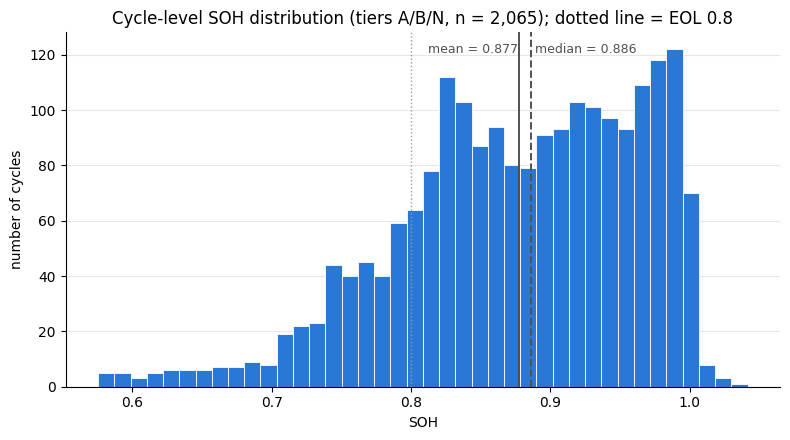

**SOH is left-skewed.** At the cycle level (n = 2,065), SOH has mean 0.877 below the median 0.886, skewness -0.64, kurtosis 3.07 (close to 3, the normal value). Most cycles are recorded while SOH is still high: Q1 = 0.822, so three quarters of the cycles have an SOH above this level. Implication: there are fewer data near the end of life, so models that forecast close to EOL have few examples to learn from; for a fleet operator this means end-of-life predictions carry the most uncertainty exactly when replacement decisions are made.

In [12]:
fig = a.plots.soh_histogram()
plt.show()
display(Markdown(a.insights.soh_distribution()))

### 4.2 Rest-time histogram (log scale)

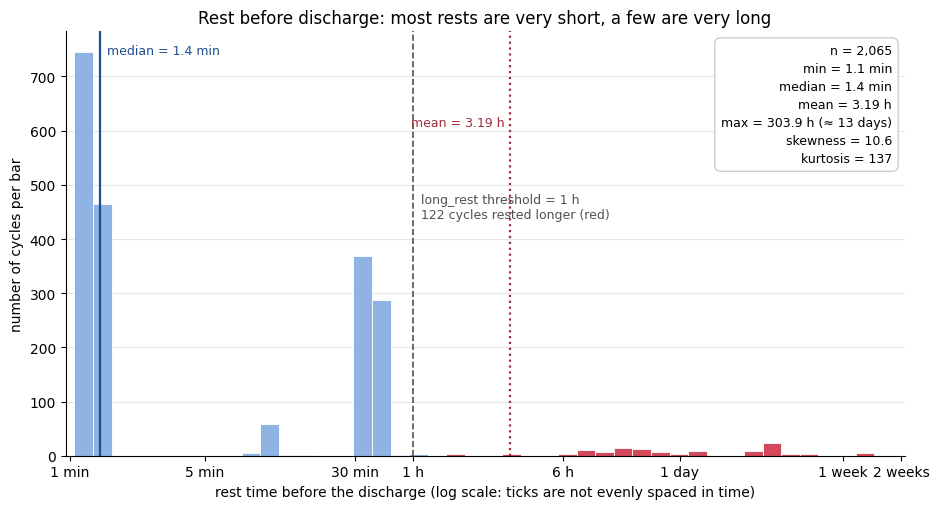

**Rest time is extremely right-skewed.** The median is only 1.4 minutes but the mean is 3.19 hours and the maximum 303.9 hours; skewness 10.6, kurtosis 137. Only 122 / 2,065 cycles (5.9%) rest longer than 1 hour. Implication: the mean must not be used to describe this variable; in a model it must be log-transformed (the SVR uses log1p) or binned (the long_rest flag), following Chap 1, p. 17.

In [13]:
fig = a.plots.rest_histogram()
plt.show()
display(Markdown(a.insights.rest_distribution()))

**How to read it:** the x axis is logarithmic, labelled in minutes, hours and days. The data form three clusters: rests of a few minutes, rests of about half an hour to one hour, and a small tail of long rests (red, above the `long_rest` threshold). The median and the mean are far apart, which is why the median is the right summary here.

### 4.3 Cell temperature by ambient temperature

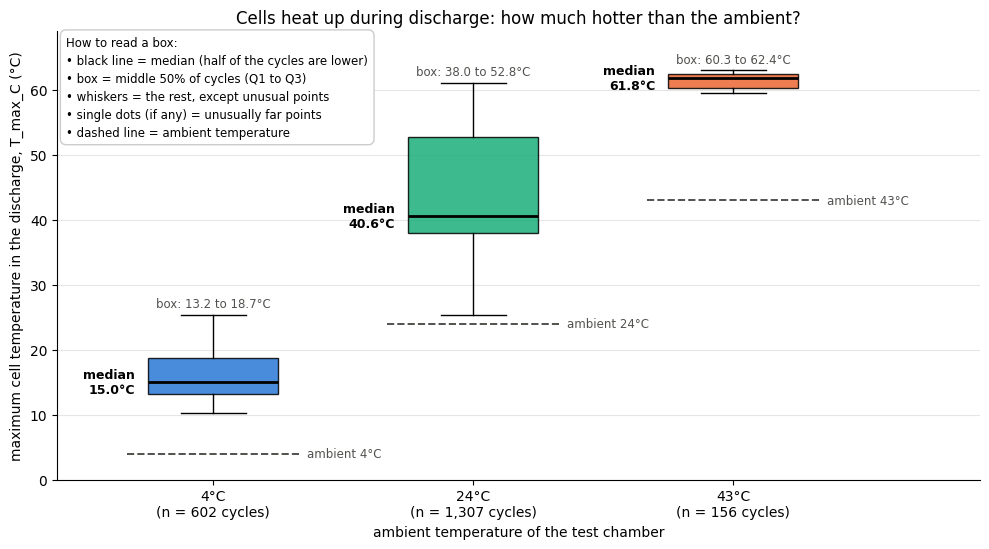

**Cells heat up during discharge, and how much depends on the ambient.** 4°C: median 15.0°C (11.0°C above ambient); 24°C: median 40.6°C (16.6°C above ambient); 43°C: median 61.8°C (18.8°C above ambient). Pooled, T_max_C has kurtosis 1.95 < 3 because it mixes 3 groups, so it must be described per ambient temperature. Implication: at 43°C ambient the cell reaches a median of 61.8°C during discharge; a cooling system for the pack is a hard requirement for vehicles used in hot climates.

In [14]:
fig = a.plots.tmax_boxplot()
plt.show()
display(Markdown(a.insights.tmax_by_temp()))

**How to read it:** the dashed line is the ambient temperature; the box shows the measured maximum cell temperature. The gap between the two is the self-heating during discharge. The 24°C box is wide because that group mixes 1, 2 and 4 A and square-wave profiles; the 43°C box is narrow because it is a single condition with few cycles.

### 4.4 Degradation rate by operating condition

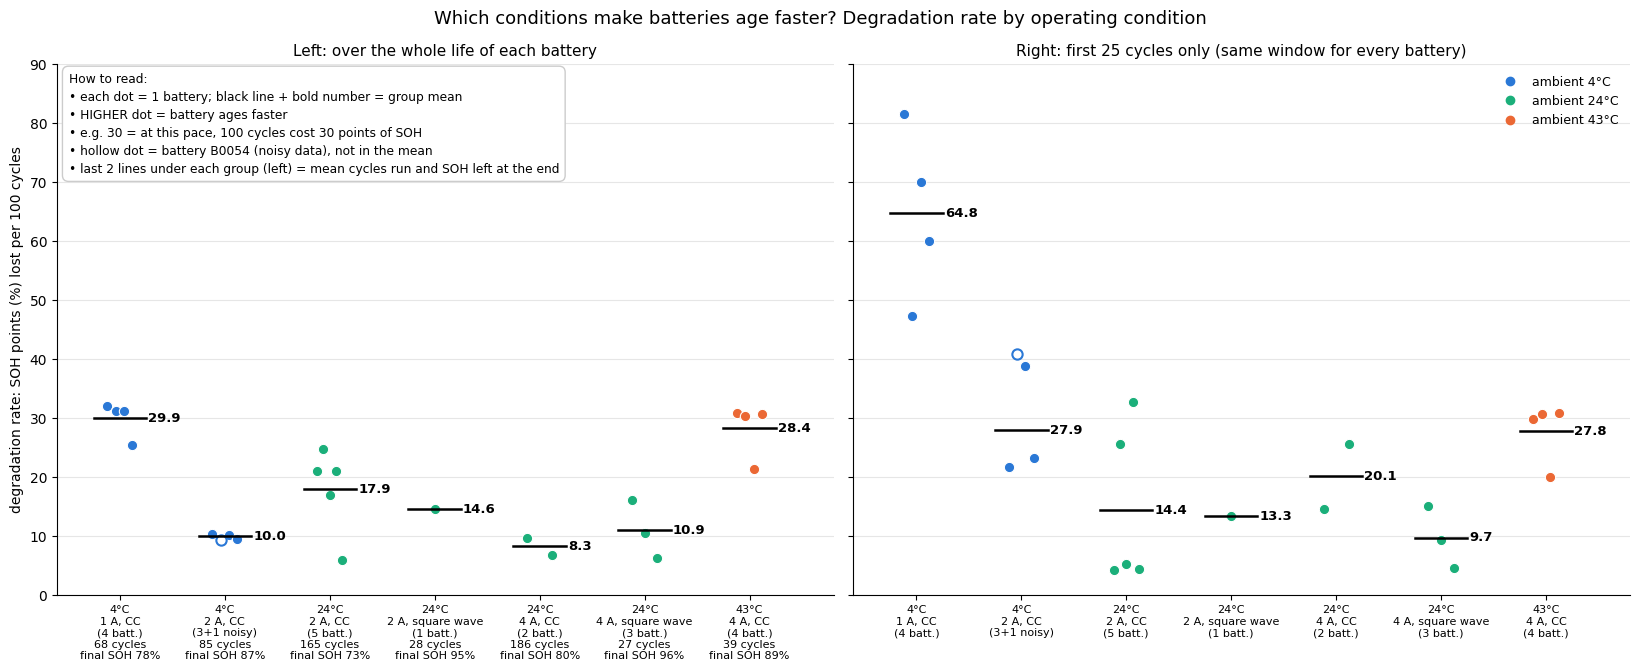

**Degradation rates differ clearly between conditions (hypothesis, to be tested in stage 3).** At the same 4 A, over the first 25 cycles, batteries at 43°C lose on average 27.8 SOH points per 100 cycles (n = 4), against 20.1 at 24°C (n = 2). At 4°C, 1 A degrades faster than 2 A: 29.9 against 10.0 over the whole series, against intuition. The ranking of the groups changes with the measure (whole series or first 25 cycles), because degradation is not linear and the groups ran different numbers of cycles; the report must show both. Each group has only 1–5 batteries, so this is a description, not a conclusion. Implication (to be confirmed in stage 3): in this data, temperature looks like a stronger lever on battery life than discharge current, so thermal management deserves priority.

In [15]:
fig = a.plots.fade_by_condition()
plt.show()
display(Markdown(a.insights.fade_by_condition()))

**How to read it:** each group has only 1–5 batteries, so each battery is a dot and the black line is the mean, instead of a boxplot (misleading with 2–3 points). The y axis is a **rate** (slope of a straight line through SOH, per 100 cycles), not the SOH lost so far; the two lines under each group in the left panel give the number of cycles actually run and the SOH left at the end. Before running the tests of stage 3, look at the spread within each group to anticipate the Levene test.

### 4.5 SOH curves over cycles

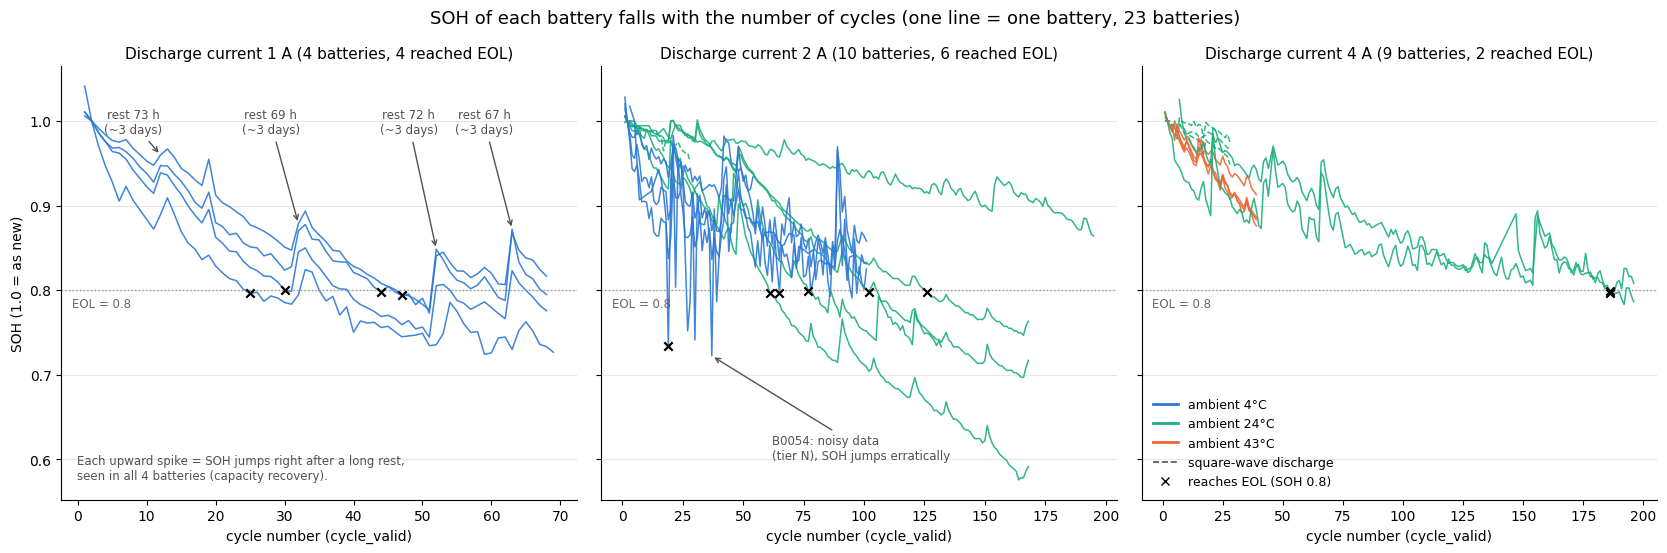

**SOH jumps up after a long rest (capacity recovery).** After a rest of more than 1 hour, 81.1% of cycles show a higher SOH than the cycle before (median change +0.0106), against a median change of -0.0031 after a short rest; the effect is seen in 18 batteries (tiers A/B/N). The gain is temporary: SOH falls back to the trend within a few cycles. Implication: these points are real behaviour, not errors, and must be kept; for warranty or resale checks, a single capacity test right after a vehicle has been parked for a long time overstates the battery's health.

In [16]:
fig = a.plots.soh_curves()
plt.show()
display(Markdown(a.insights.recovery_after_rest()))

**How to read it:** each line is one battery; panels are discharge currents, colour is ambient temperature, dashed lines are square-wave discharges, and ✕ marks the first cycle below SOH 0.8. The batteries ran very different numbers of cycles, so degradation rates must also be compared on a common window (first 25 cycles). The upward spikes in the 1 A panel follow rests of about 3 days in all four batteries (capacity recovery). The erratic 4°C / 2 A line is B0054 (tier N, noisy data).

### 4.6 Impedance against SOH (G1)

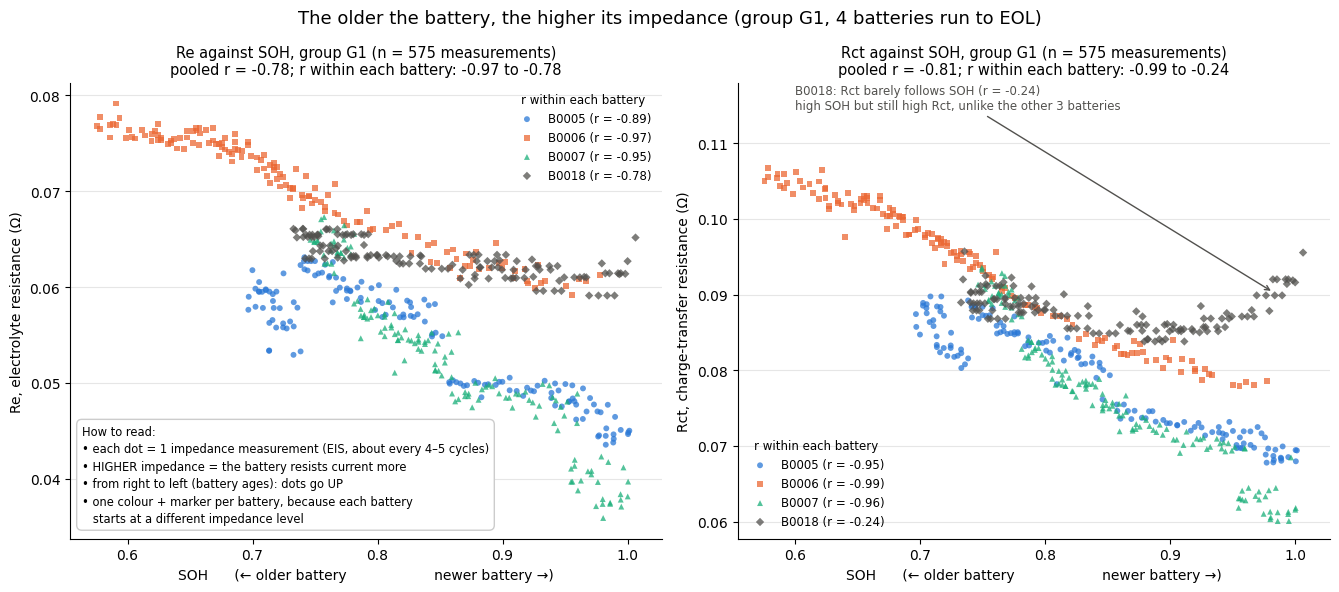

**Impedance rises as the battery ages.** In G1 (4 batteries), the pooled Pearson correlation between SOH and Re is -0.78, and between SOH and Rct -0.81. Within each battery, r with Re ranges from -0.97 to -0.78, and with Rct from -0.99 to -0.24; the exception is B0018 (r with Rct only -0.24, Rct barely follows SOH). In the figure the points form one cluster per battery: each battery starts at a different impedance level, so the pooled r mixes differences between batteries with the ageing trend within each battery. Implication: impedance reflects ageing and supports the SEM model (operating conditions → impedance → SOH), but a battery's impedance should be compared with its own starting value; a fixed impedance threshold for all packs would misjudge some of them. Cycles within a battery are dependent, so r here is descriptive only, without p-values.

In [17]:
fig = a.plots.impedance_scatter()
plt.show()
display(Markdown(a.insights.impedance()))

**How to read it:** each dot is one impedance measurement (EIS); moving from right to left the battery ages and the dots go up. Each battery has its own colour and marker because each starts at a different impedance level; that is why the pooled r and the within-battery r differ, and why B0018 (Rct barely follows SOH) must be mentioned when impedance is used in the SEM model.

## 5. Insights (WBS C1.7)

All insights in one place, in the format of slide Chap 1, p. 60 (finding → number → implication). The comparisons between conditions are descriptive hypotheses; whether the differences are statistically significant is tested in stage 3 (Tien Hung lead) on `battery_fade.csv`.

In [18]:
for text in a.insights.all():
    display(Markdown("- " + text))

- **SOH is left-skewed.** At the cycle level (n = 2,065), SOH has mean 0.877 below the median 0.886, skewness -0.64, kurtosis 3.07 (close to 3, the normal value). Most cycles are recorded while SOH is still high: Q1 = 0.822, so three quarters of the cycles have an SOH above this level. Implication: there are fewer data near the end of life, so models that forecast close to EOL have few examples to learn from; for a fleet operator this means end-of-life predictions carry the most uncertainty exactly when replacement decisions are made.

- **Rest time is extremely right-skewed.** The median is only 1.4 minutes but the mean is 3.19 hours and the maximum 303.9 hours; skewness 10.6, kurtosis 137. Only 122 / 2,065 cycles (5.9%) rest longer than 1 hour. Implication: the mean must not be used to describe this variable; in a model it must be log-transformed (the SVR uses log1p) or binned (the long_rest flag), following Chap 1, p. 17.

- **SOH jumps up after a long rest (capacity recovery).** After a rest of more than 1 hour, 81.1% of cycles show a higher SOH than the cycle before (median change +0.0106), against a median change of -0.0031 after a short rest; the effect is seen in 18 batteries (tiers A/B/N). The gain is temporary: SOH falls back to the trend within a few cycles. Implication: these points are real behaviour, not errors, and must be kept; for warranty or resale checks, a single capacity test right after a vehicle has been parked for a long time overstates the battery's health.

- **Cells heat up during discharge, and how much depends on the ambient.** 4°C: median 15.0°C (11.0°C above ambient); 24°C: median 40.6°C (16.6°C above ambient); 43°C: median 61.8°C (18.8°C above ambient). Pooled, T_max_C has kurtosis 1.95 < 3 because it mixes 3 groups, so it must be described per ambient temperature. Implication: at 43°C ambient the cell reaches a median of 61.8°C during discharge; a cooling system for the pack is a hard requirement for vehicles used in hot climates.

- **Degradation rates differ clearly between conditions (hypothesis, to be tested in stage 3).** At the same 4 A, over the first 25 cycles, batteries at 43°C lose on average 27.8 SOH points per 100 cycles (n = 4), against 20.1 at 24°C (n = 2). At 4°C, 1 A degrades faster than 2 A: 29.9 against 10.0 over the whole series, against intuition. The ranking of the groups changes with the measure (whole series or first 25 cycles), because degradation is not linear and the groups ran different numbers of cycles; the report must show both. Each group has only 1–5 batteries, so this is a description, not a conclusion. Implication (to be confirmed in stage 3): in this data, temperature looks like a stronger lever on battery life than discharge current, so thermal management deserves priority.

- **Impedance rises as the battery ages.** In G1 (4 batteries), the pooled Pearson correlation between SOH and Re is -0.78, and between SOH and Rct -0.81. Within each battery, r with Re ranges from -0.97 to -0.78, and with Rct from -0.99 to -0.24; the exception is B0018 (r with Rct only -0.24, Rct barely follows SOH). In the figure the points form one cluster per battery: each battery starts at a different impedance level, so the pooled r mixes differences between batteries with the ageing trend within each battery. Implication: impedance reflects ageing and supports the SEM model (operating conditions → impedance → SOH), but a battery's impedance should be compared with its own starting value; a fixed impedance threshold for all packs would misjudge some of them. Cycles within a battery are dependent, so r here is descriptive only, without p-values.

- **Batteries differ from the start.** C0 of the 4 G1 batteries (same conditions) ranges from 1.852 to 2.037 Ah, a spread of 10.0%; 3 / 4 batteries are below the rated 2.0 Ah. B0045 has a C0 of only 1.031 Ah, while the other batteries of group G7 have 1.501–1.559 Ah, most likely a defective cell from the start. Implication: SOH must be normalised by each battery's own C0, not by 2.0 Ah; for warranty, the spread between cells is a risk of its own and incoming cells should be screened.

- **Almost half of the batteries never reach EOL in the data.** Only 12 / 23 batteries fall below SOH 0.8 (column cycles_to_soh80); the other 11 stop earlier. Several groups stop together after the same number of cycles (24°C, 4 A, square wave: 3 batteries stopped after 25–28 cycles; 43°C, 4 A, CC: 4 batteries stopped after 39 cycles), which points to the experiment being ended, not to the batteries failing; the dataset does not record why. Implication: the mean of cycles_to_soh80 must not be read as the lifetime of all batteries (the data are censored), and a condition with few batteries at EOL is not a 'gentler' condition.

## 6. Notes

- **Figure names:** the prefix `desc_` avoids clashing with the `fig1`–`fig6` figures that `src/eda_dataset.py` (Leader) is expected to produce; `fig2`–`fig4` need the raw `.mat` data and are not made here.
- **The capacity-recovery insight** is computed on the tier A/B/N rows of this notebook. `notebooks/31_iforest.ipynb` uses tiers A/B only, so its shares differ slightly; both are computed from the data.
- **Comparisons between conditions are descriptive only.** Whether they are statistically significant is the job of stage 3.